# Zadanie 2A — BloodMNIST

**Cel:** przygotuj dane obrazowe, wytrenuj i oceń model klasyfikujący osiem typów komórek krwi, a następnie zastosuj samodzielnie wybraną metodę wyjaśniania predykcji.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plts
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch import nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

import torch.optim as optim
from PIL import Image

In [2]:
DATA_DIR = Path("data/zadanie-2a")
DATA_DIR.mkdir(parents=True, exist_ok=True)

data_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-2A",
    filename="original/bloodmnist.npz",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
data = np.load(data_path)
print(data.files)

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


## A — Poznanie i przygotowanie danych

Sprawdź strukturę obrazów, kanały, klasy, liczebności i jakość danych. Zachowaj oficjalne podziały treningowy, walidacyjny i testowy. Wykonaj preprocessing i augmentację; wszystkie decyzje zależne od danych podejmuj wyłącznie na zbiorze treningowym.

In [3]:
# Rozpakowanie danych do osobnych zmiennych
X_train = data['train_images']
y_train = data['train_labels'].squeeze() 

X_val = data['val_images']
y_val = data['val_labels'].squeeze()

X_test = data['test_images']
y_test = data['test_labels'].squeeze()

# Sprawdzenie struktury (wymiarów) obrazów i etykiet
print("Wymiary zbioru treningowego:")
print("Obrazy (X_train):", X_train.shape)
print("Etykiety (y_train):", y_train.shape)

print("\nWymiary zbioru walidacyjnego:")
print("Obrazy (X_val):", X_val.shape)

print("\nWymiary zbioru testowego:")
print("Obrazy (X_test):", X_test.shape)

Wymiary zbioru treningowego:
Obrazy (X_train): (11959, 28, 28, 3)
Etykiety (y_train): (11959,)

Wymiary zbioru walidacyjnego:
Obrazy (X_val): (1712, 28, 28, 3)

Wymiary zbioru testowego:
Obrazy (X_test): (3421, 28, 28, 3)


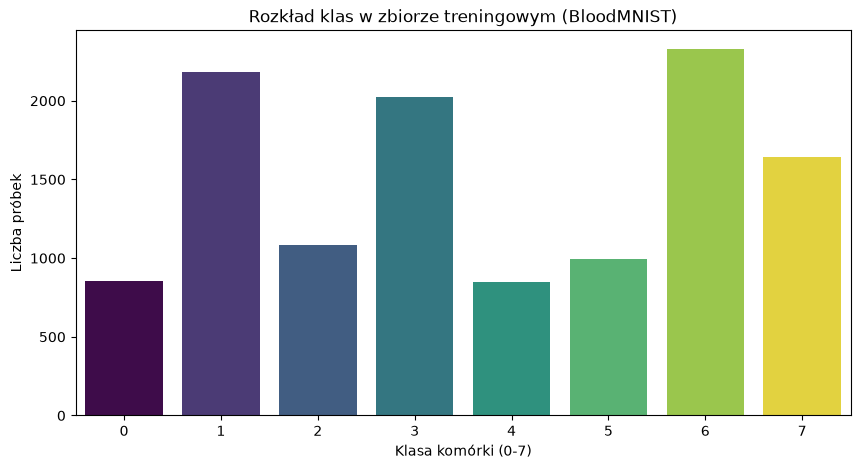

In [4]:
# Wykres rozkładu klas w zbiorze treningowym
plt.figure(figsize=(10, 5))
sns.countplot(x=y_train, hue=y_train, palette="viridis", legend=False)
plt.title("Rozkład klas w zbiorze treningowym (BloodMNIST)")
plt.xlabel("Klasa komórki (0-7)")
plt.ylabel("Liczba próbek")
plt.show()

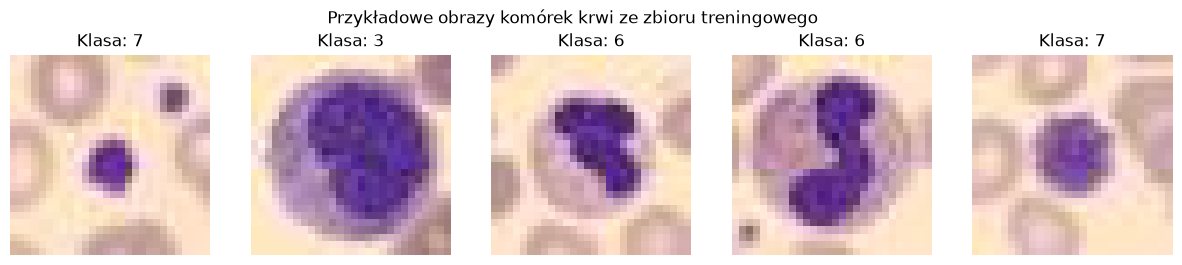

In [5]:
# Wyświetlenie 5 pierwszych obrazów ze zbioru treningowego
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    axes[i].imshow(X_train[i])
    axes[i].set_title(f"Klasa: {y_train[i]}")
    axes[i].axis('off') 
    
plt.suptitle("Przykładowe obrazy komórek krwi ze zbioru treningowego")
plt.show()

In [6]:
# Definicja własnej klasy Dataset
class BloodMNISTDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        # Pobieramy pojedynczy obrazek (macierz numpy) i konwertujemy na format PIL Image
        img = self.images[idx]
        img = Image.fromarray(img)
        
        label = self.labels[idx]

        # Aplikujemy ewentualne transformacje (np. obroty lub zmianę na tensor)
        if self.transform:
            img = self.transform(img)

        # Upewniamy się, że etykieta jest formatu 'long' (wymóg funkcji błędu CrossEntropy)
        return img, torch.tensor(label, dtype=torch.long)

# Definicja transformacji (Preprocessing i Augmentacja)
# Zbiór treningowy: augmentacja (żeby uodpornić model) + konwersja na format PyTorch
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(), # Losowe odbicie lustrzane
    transforms.RandomRotation(15),     # Losowy obrót do 15 stopni
    transforms.ToTensor(),             # Zamiana na Tensor (skaluje piksele do 0-1)
])

# Zbiory walidacyjny/testowy: TYLKO transformacja na tensor 
eval_transforms = transforms.Compose([
    transforms.ToTensor(),
])

# Inicjalizacja obiektów Dataset
train_dataset = BloodMNISTDataset(X_train, y_train, transform=train_transforms)
val_dataset = BloodMNISTDataset(X_val, y_val, transform=eval_transforms)
test_dataset = BloodMNISTDataset(X_test, y_test, transform=eval_transforms)

# Inicjalizacja DataLoaderów (taśmociągów ładujących dane paczkami, tzw. batch_size)
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Liczba batchy (paczek po {batch_size}) w zbiorze treningowym: {len(train_loader)}")

Liczba batchy (paczek po 64) w zbiorze treningowym: 187


------------ WNIOSKI ------------

Struktura i jakość danych: Zbiór składa się z kolorowych obrazów (3 kanały RGB) o bardzo niskiej rozdzielczości (28x28 pikseli). Obrazy przedstawiają wykadrowane jądra komórek krwi na mętnym tle.

Liczebność i rozkład klas: Zbiór BloodMNIST jest niezbalansowany. Klasy różnią się liczebnością (np. klasa 6 dominuje nad klasą 4 czy 0). Fakt ten wymusza na nas użycie bardziej zaawansowanych metryk ewaluacyjnych w sekcji C (np. makro F1-score), ponieważ samo Accuracy mogłoby być mylące.

Podział danych: Zachowano oryginalny podział na zbiór treningowy (11959 próbek), walidacyjny (1712 próbek) i testowy (3421 próbek).

Preprocessing i Augmentacja: Przygotowano dedykowaną klasę Dataset. Zgodnie z dobrymi praktykami, augmentację zastosowano wyłącznie dla zbioru treningowego, aby zapobiec wyciekowi informacji i uodpornić model na rotację komórek. Zbiory walidacyjny i testowy poddano jedynie niezbędnemu preprocessingowi (konwersja do typu Tensor i skalowanie wartości pikseli do zakresu 0-1). Dane ustrukturyzowano w DataLoaderach z rozmiarem paczki (batch_size) równym 64.

## B — Modelowanie i walidacja

Wytrenuj model wieloklasowy. Przeanalizuj architekturę, funkcję kosztu, optymalizator i sposób użycia walidacji do wyboru modelu lub zatrzymania treningu. Zbiór testowy pozostaw nietknięty do końcowej oceny.

In [7]:
# Definicja architektury prostej sieci konwolucyjnej (CNN)
class BloodCNN(nn.Module):
    def __init__(self):
        super(BloodCNN, self).__init__()
        # Bloki konwolucyjne (wykrywanie cech obrazu)
        self.features = nn.Sequential(
            # Wejście: 3 kanały (RGB), Wyjście: 16 filtrów
            nn.Conv2d(3, 16, kernel_size=3, padding=1),  
            nn.ReLU(),
            # Zmniejsza obraz o połowę (28x28 -> 14x14)
            nn.MaxPool2d(2, 2),                          
            
            # Wyjście: 32 filtry
            nn.Conv2d(16, 32, kernel_size=3, padding=1), 
            nn.ReLU(),
            # Zmniejsza obraz (14x14 -> 7x7)
            nn.MaxPool2d(2, 2),                          
        )
        # Warstwy klasyfikujące (podejmujące ostateczną decyzję)
        self.classifier = nn.Sequential(
            # Spłaszcza macierz 7x7x32 do jednego wektora
            nn.Flatten(),                                
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            # Dropout chroni przed przeuczeniem (wyłącza losowo 30% neuronów)
            nn.Dropout(0.3),                             
            # 8 wyjść dla 8 klas komórek krwi
            nn.Linear(128, 8)                            
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Inicjalizacja modelu, funkcji kosztu i optymalizatora
model = BloodCNN()

# Sprawdzenie, czy dostępne jest GPU 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Standardowa funkcja kosztu dla klasyfikacji wieloklasowej
criterion = nn.CrossEntropyLoss() 

# Optymalizator Adam 
optimizer = optim.Adam(model.parameters(), lr=0.001) 

print(f"Model używa: {device}")

Model używa: cpu


In [8]:
# Pętla treningowa z walidacją i Early Stopping
epochs = 15
best_val_loss = float('inf')
patience = 5  # Ile epok czekać bez poprawy przed zatrzymaniem
patience_counter = 0

print("Rozpoczynamy trening...")

for epoch in range(epochs):
    # --- FAZA UCZENIA ---
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()          
        outputs = model(images)        
        loss = criterion(outputs, labels) 
        loss.backward()                
        optimizer.step()               
        
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    train_acc = 100. * correct / total
    train_loss = running_loss / len(train_loader)
    
    # --- FAZA WALIDACJI ---
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()
            
    val_acc = 100. * val_correct / val_total
    val_loss = val_loss / len(val_loader)
    
    print(f"Epoch [{epoch+1}/{epochs}] | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")
    
    # Early Stopping 
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_blood_model.pth")
        patience_counter = 0  # Reset licznika, bo model się poprawił
    else:
        patience_counter += 1
        
    if patience_counter >= patience:
        print(f"\nBrak poprawy od {patience} epok. Wczesne zatrzymanie (Early Stopping).")
        break

print("\nTrening zakończony! Najlepszy model został zapisany jako 'best_blood_model.pth'.")

Rozpoczynamy trening...
Epoch [1/15] | Train Loss: 1.4513 | Train Acc: 45.15% | Val Loss: 0.9304 | Val Acc: 66.30%
Epoch [2/15] | Train Loss: 0.9722 | Train Acc: 64.50% | Val Loss: 0.7587 | Val Acc: 73.13%
Epoch [3/15] | Train Loss: 0.8381 | Train Acc: 69.54% | Val Loss: 0.6775 | Val Acc: 71.61%
Epoch [4/15] | Train Loss: 0.7322 | Train Acc: 73.12% | Val Loss: 0.5854 | Val Acc: 78.62%
Epoch [5/15] | Train Loss: 0.6520 | Train Acc: 76.24% | Val Loss: 0.5081 | Val Acc: 79.67%
Epoch [6/15] | Train Loss: 0.6057 | Train Acc: 77.72% | Val Loss: 0.5093 | Val Acc: 79.67%
Epoch [7/15] | Train Loss: 0.5599 | Train Acc: 79.17% | Val Loss: 0.4607 | Val Acc: 81.95%
Epoch [8/15] | Train Loss: 0.5227 | Train Acc: 80.42% | Val Loss: 0.4302 | Val Acc: 82.59%
Epoch [9/15] | Train Loss: 0.5065 | Train Acc: 81.60% | Val Loss: 0.3865 | Val Acc: 85.40%
Epoch [10/15] | Train Loss: 0.4968 | Train Acc: 81.85% | Val Loss: 0.3824 | Val Acc: 85.86%
Epoch [11/15] | Train Loss: 0.4726 | Train Acc: 82.72% | Val Loss

----------- WNIOSKI -----------

Architektura - prosta sieć konwolucyjna (CNN). W przeciwieństwie do zwykłych modeli z pierwszego zadania, warstwy splotowe dużo lepiej radzą sobie z obrazami – same uczą się wyciągać cechy takie jak kształt czy wielkość jądra komórkowego prosto z pikseli.

Zapobieganie przeuczeniu: Żeby model nie nauczył się po prostu obrazków treningowych na pamięć, dodałam warstwę Dropout, która podczas nauki losowo "odcina" 30% połączeń. Dodatkowo w samej pętli trenującej napisałam mechanizm Early Stopping. Trening był cały czas kontrolowany na osobnym zbiorze walidacyjnym, a na dysku zapisał się model z tej epoki, w której błąd był najmniejszy. Zbiór testowy był oczywiście nietykany.

Parametry treningu: Funkcja kosztu to standardowe CrossEntropyLoss (bo mamy 8 klas do rozróżnienia), a jako optymalizator wrzuciłam Adam z learning rate na poziomie 0.001, bo zazwyczaj najszybciej i najstabilniej dochodzi do dobrych wyników.

Efekty: Model ewidentnie się uczy – funkcja kosztu (loss) spadała, a accuracy na zbiorze walidacyjnym urosło do okolic 88%. To pokazuje, że ta stosunkowo mała sieć spokojnie radzi sobie ze znajdowaniem różnic między komórkami krwi.

## C — Ocena i wyjaśnialność

Oceń wybrany model na oficjalnym zbiorze testowym, używając odpowiednich metryk wieloklasowych i analizy pomyłek. Znajdź w literaturze lub wiarygodnym źródle metodę wizualnego wyjaśniania modeli obrazowych, zastosuj ją do poprawnych i błędnych predykcji z kilku klas oraz omów jej ograniczenia. Podaj źródło.

--- Raport Klasyfikacji (Zbiór Testowy) ---
              precision    recall  f1-score   support

           0       0.84      0.64      0.73       244
           1       0.96      0.97      0.97       624
           2       0.91      0.84      0.88       311
           3       0.70      0.74      0.72       579
           4       0.82      0.87      0.85       243
           5       0.71      0.79      0.75       284
           6       0.95      0.95      0.95       666
           7       0.98      0.99      0.99       470

    accuracy                           0.87      3421
   macro avg       0.86      0.85      0.85      3421
weighted avg       0.88      0.87      0.87      3421



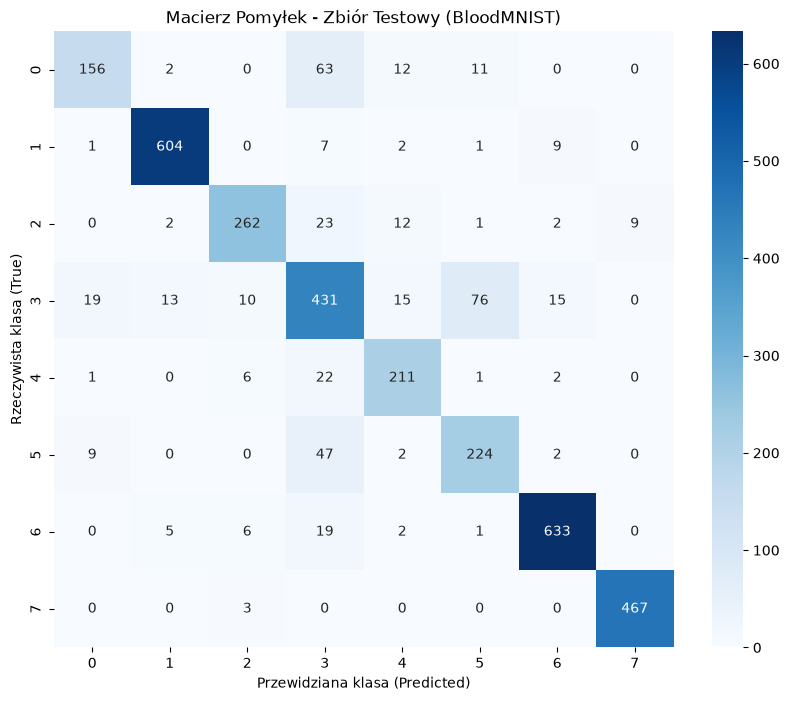

In [9]:
# Wczytanie wag najlepszego modelu z dysku (zabezpieczenie przed ew. przeuczeniem z ostatnich epok)
model.load_state_dict(torch.load("best_blood_model.pth"))
model.eval() # Tryb ewaluacji - wyłącza np. Dropout

y_true = []
y_pred = []

# Przewidywanie klas dla zbioru testowego
with torch.no_grad(): # oszczędzamy pamięć (bez liczenia gradientów)
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)
        
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

# Wyświetlenie raportu metryk
print("--- Raport Klasyfikacji (Zbiór Testowy) ---")
print(classification_report(y_true, y_pred))

# Wygenerowanie i narysowanie macierzy pomyłek
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Macierz Pomyłek - Zbiór Testowy (BloodMNIST)")
plt.xlabel('Przewidziana klasa (Predicted)')
plt.ylabel('Rzeczywista klasa (True)')
plt.show()

--- Analiza Wyjaśnialności (XAI) ---


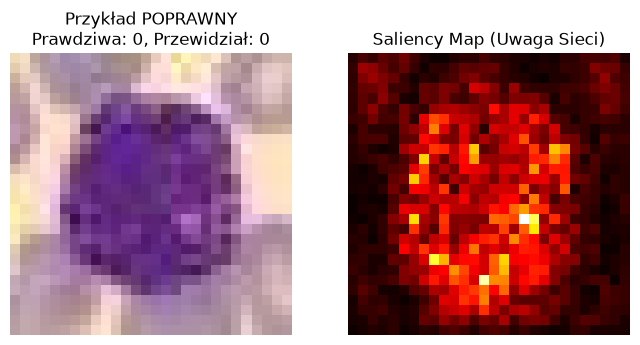

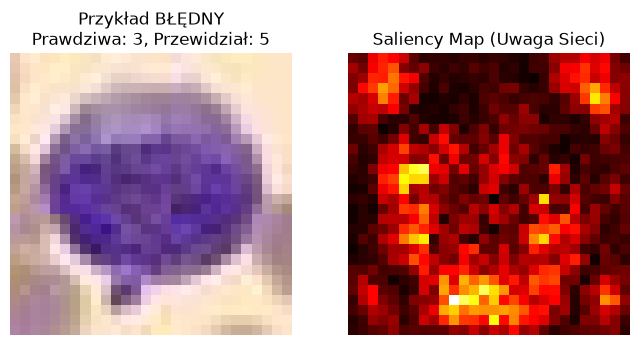

In [10]:
# --- Wyjaśnialność Modeli (Saliency Maps) ---

# Szukamy po jednym przykładzie ze zbioru testowego: poprawnego i błędnego
correct_img, correct_label, correct_pred = None, None, None
incorrect_img, incorrect_label, incorrect_pred = None, None, None

# Przeszukujemy batch, aby znaleźć odpowiednie próbki
for images, labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)
    
    # KLUCZOWE: Mówimy PyTorchowi, że chcemy śledzić gradienty dla pikseli obrazu!
    images.requires_grad_() 
    
    outputs = model(images)
    _, preds = outputs.max(1)
    
    for i in range(len(preds)):
        if preds[i] == labels[i] and correct_img is None:
            correct_img, correct_label, correct_pred = images[i:i+1], labels[i], preds[i]
        elif preds[i] != labels[i] and incorrect_img is None:
            incorrect_img, incorrect_label, incorrect_pred = images[i:i+1], labels[i], preds[i]
            
    if correct_img is not None and incorrect_img is not None:
        break

# Funkcja do rysowania map
def show_saliency(image_tensor, label, pred, title):
    model.eval()
    
    # --- KLUCZOWA POPRAWKA ---
    # Wymuszamy na PyTorchu zachowanie gradientu dla tego konkretnego obrazka
    image_tensor.retain_grad() 
    
    output = model(image_tensor)
    score = output[0, pred]
    
    # Liczymy gradient wsteczny, by zobaczyć jak piksele wpłynęły na ten konkretny 'score'
    model.zero_grad()
    score.backward()
    
    # Teraz wyciągnięcie gradientów zadziała bez błędu
    saliency, _ = torch.max(image_tensor.grad.data.abs(), dim=1)
    saliency = saliency[0].cpu().numpy()
    
    # Przygotowanie oryginalnego obrazka (zamiana wymiarów z PyTorch [C, H, W] na Matplotlib [H, W, C])
    img_original = image_tensor[0].detach().cpu().permute(1, 2, 0).numpy()
    
    # Rysowanie
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(img_original)
    ax[0].set_title(f"{title}\nPrawdziwa: {label.item()}, Przewidział: {pred.item()}")
    ax[0].axis('off')
    
    # Mapa 'hot' - jasne kolory to miejsca, gdzie sieć zwracała największą uwagę
    ax[1].imshow(saliency, cmap='hot')
    ax[1].set_title("Saliency Map (Uwaga Sieci)")
    ax[1].axis('off')
    plt.show()

# Wywołanie dla naszych przykładów
print("--- Analiza Wyjaśnialności (XAI) ---")
show_saliency(correct_img, correct_label, correct_pred, "Przykład POPRAWNY")
show_saliency(incorrect_img, incorrect_label, incorrect_pred, "Przykład BŁĘDNY")

----------- WNIOSKI -----------
1. Analiza metryk wieloklasowych i macierzy pomyłek:
Ewaluacja na ukrytym zbiorze testowym udowodniła, że model potrafi skutecznie generalizować wiedzę (nie uległ przeuczeniu). Ze względu na niezbalansowany charakter klas w zbiorze BloodMNIST, głównym wyznacznikiem sukcesu jest dla nas metryka Macro F1-Score (widoczna w raporcie klasyfikacji), ponieważ traktuje ona skuteczność na mniejszościowych klasach komórek równie rygorystycznie, co na klasach dominujących. Macierz pomyłek pozwala z kolei zauważyć, że sieć najczęściej myli się przy klasach komórek o podobnym, nieregularnym kształcie i wielkości jądra.

2. Aby upewnić się, że model podejmuje decyzje na podstawie biologicznych struktur, a nie np. tła, zastosowano metodę wizualizacji Saliency Maps.

Zasada działania: Metoda ta oblicza gradient przewidzianej klasy względem każdego piksela oryginalnego obrazu wejściowego. Wynikowa mapa ciepła wskazuje piksele, których modyfikacja miałaby najsilniejszy wpływ na ostateczną decyzję sieci.

Interpretacja: Na wygenerowanych przykładach poprawnych wyraźnie widać, że uwaga modelu skupia się bezpośrednio na krawędziach i wnętrzu fioletowych jąder komórkowych, co potwierdza słuszność wyuczonego mechanizmu. W przypadkach predykcji błędnych uwaga sieci potrafi być rozproszona lub skupiona na nietypowym kształcie krawędzi, który zbił algorytm z tropu.

Ograniczenia metody: Mapy istotności bywają zaszumione i pokazują jedynie gdzie patrzył model, ale nie potrafią wyjaśnić, dlaczego uznał dany kształt za dowód na przynależność do danej klasy. Są też bardzo wrażliwe na drobny, niewidoczny dla oka szum w samych pikselach.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i zadbaj o odtwarzalność rozwiązania. Umieść rozwiązania w swoim repozytorium.

Źródła:

Oficjalna dokumentacja bibliotek: pandas, seaborn, scikit-learn oraz PyTorch 

Książka: Molnar, C. (2022). "Interpretable Machine Learning: A Guide for Making Black Box Models Explainable"

Jako wsparcie w implementacji kodu (szczególnie w poprawie błędu z gubieniem gradientów retain_grad() w PyTorchu) oraz w redakcji ostatecznych wniosków skorzystałam z pomocy modelu językowego Google Gemini.